# 냥기사의 여행 LoRA 학습 데이터 생성 (NAI API)

냥기사의 여행 그림체 LoRA 학습용 이미지 800장을 NAI API로 생성한다.

- 생성 조건은 기존 NAI 이미지 17장의 PNG 메타데이터(Comment)에 기록된 값과 같게 맞춘다.
- 요청 형식은 사용 중인 Risu의 NAI 이미지 모듈 구현(`src/ts/process/stableDiff.ts`)과 같게 맞춘다.
- API 키는 프로젝트 루트 `.env`의 `NAI_API_KEY`에서 읽는다.
- 1장을 먼저 생성해 Anlas 변화, 모델 버전, 그림체를 확인한 뒤 전체를 생성한다.
- 생성 결과는 1장마다 `gen_log.csv`에 추가 저장한다. 중단 후 다시 실행하면 이미 만든 번호는 건너뛴다.
- 평가용 프롬프트(LoRA 학습 후 스타일 유지 평가용)와 겹치는 문구는 학습 데이터에 넣지 않는다.

## 의존성 설치

In [1]:
%pip install -U requests python-dotenv pandas matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


## 설정

In [15]:
import base64
import io
import json
import os
import random
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from dotenv import load_dotenv
from PIL import Image

ROOT = Path('..')
NAI_DIR = ROOT / 'data' / 'raw' / 'nai'
GEN_DIR = NAI_DIR / 'lora_gen'
GEN_DIR.mkdir(parents=True, exist_ok=True)
LOG_CSV = GEN_DIR / 'gen_log.csv'

load_dotenv(ROOT / '.env')
API_KEY = os.getenv('NAI_API_KEY')
assert API_KEY, '프로젝트 루트 .env에 NAI_API_KEY=... 을 넣어야 함'
HEADERS = {'Authorization': f'Bearer {API_KEY}', 'Content-Type': 'application/json'}

# Risu NAI 모듈 기본 주소 (database.svelte.ts NAIImgUrl 기본값)
GEN_URL = 'https://image.novelai.net/ai/generate-image'
# Anlas 잔액 조회: trainingStepsLeft.fixedTrainingStepsLeft + purchasedTrainingSteps (novelai-python SDK user/subscription)
SUB_URL = 'https://image.novelai.net/user/subscription'

# 기존 V4.5 이미지 14장 메타데이터 값 그대로 사용 (Source: NovelAI Diffusion V4.5 C02D4F98)
MODEL = 'nai-diffusion-4-5-full'
EXPECTED_SOURCE = 'NovelAI Diffusion V4.5 C02D4F98'
WIDTH, HEIGHT = 1024, 1024
STEPS = 23
SCALE = 5.0
SAMPLER = 'k_euler_ancestral'
NOISE_SCHEDULE = 'karras'
# 웹 UI의 품질 태그 토글이 프롬프트 끝에 붙이던 문자열 (메타데이터 prompt 끝부분과 동일)
QUALITY_SUFFIX = 'very aesthetic, masterpiece, no text, -0.8::feet::, rating:general'
# 메타데이터 uc (14장 모두 동일)
UC = ('blurry, lowres, upscaled, artistic error, film grain, scan artifacts, worst quality, bad quality, jpeg artifacts, '
      'very displeasing, chromatic aberration, halftone, multiple views, logo, too many watermarks, negative space, blank page, '
      'text, watermark, signature, logo, realistic, 3d, photorealistic, painterly, sketch, blurry, lowres, bad anatomy, '
      'extra limbs, extra tail, witch hat, pointed hat, bow, ribbon')

# Precise Reference(character&style)에 넣을 기준 이미지. 기존 생성 때 쓴 파일을 직접 지정해야 함 (메타데이터에 파일 정보가 없음)
REF_IMAGE = NAI_DIR / 'no humans, animal focus, a small black cat adventurer standing upright on two le s-4048534430.png'
USE_PRECISE_REFERENCE = True
assert (not USE_PRECISE_REFERENCE) or REF_IMAGE, 'REF_IMAGE에 기준 이미지 경로를 지정해야 함'
print('ref:', REF_IMAGE)

ref: ..\data\raw\nai\no humans, animal focus, a small black cat adventurer standing upright on two le s-4048534430.png


## 학습용 프롬프트 800개

기존 NAI 프롬프트 세트의 학습용 비율(주인공 6 : 조연·적 7 : 배경 4 : 스크린샷풍 2 : 아이템 1)을 800장으로 늘린다. 캐릭터 고정 태그와 그림체 태그는 기존 프롬프트와 같고, 행동·장소·시간대·구도만 바꾼다.

In [16]:
STYLE = 'flat color, cel shading, clean thin lineart, soft bright colors, storybook fantasy, anime style, very aesthetic, masterpiece, no text'
CAT = ('no humans, black cat adventurer, yellow eyes, red wide-brim hat, ears through headwear, olive green capelet, '
       'brown cross-shaped clasp, brown belt, short sword at hip, olive green cape with shield emblem')

CAT_ACTIONS = ['standing upright, looking at viewer', 'walking, standing upright', 'running forward', 'jumping',
               'sitting on a rock', 'drawing a short sword', 'swinging a sword', 'holding a round shield',
               'reading a large map', 'eating a fish', 'drinking from a wooden mug', 'waving a paw',
               'pointing forward', 'looking up at the sky', 'crouching low, sneaking', 'carrying a small backpack',
               'resting with eyes closed', 'holding a lantern', 'stretching arms', 'kneeling on one knee']
CAT_PLACES = ['green fields with a dirt road', 'small village square, red roofed houses', 'deep forest',
              'stone dungeon corridor', 'cozy tavern interior', 'mountain path', 'riverside with reeds', 'castle gate',
              'flower meadow', 'wooden bridge over a stream', 'rainy forest', 'autumn forest, falling leaves']
TIMES = ['daytime', 'morning light', 'night, starry sky']
CAMERAS = ['full body, wide shot', 'full body', 'cowboy shot']

SUPPORT = {
    'rabbit': ('no humans, white rabbit merchant, round glasses, brown apron, large backpack full of goods, standing upright',
               ['arranging goods on a wooden cart', 'counting coins', 'holding up a potion bottle', 'waving', 'walking with a heavy backpack',
                'reading a ledger', 'sitting and resting', 'laughing', 'pointing at a map', 'carrying a wooden crate'],
               ['village street', 'forest road', 'tavern interior', 'town gate', 'riverside', 'hilltop with a windmill', 'wooden shop interior']),
    'owl': ('no humans, old grey owl wizard, long blue robe, wooden staff, small round hat',
            ['reading a glowing book', 'casting a spell with the staff', 'stirring a bubbling cauldron', 'writing with a quill',
             'looking through a telescope', 'holding a crystal orb', 'walking with the staff', 'raising one wing, teaching',
             'sitting in an armchair', 'sleeping on a pile of books'],
            ['cluttered tower library', 'stone tower rooftop', 'forest clearing', 'tavern interior', 'magic workshop', 'ancient ruins', 'village square']),
    'dog': ('no humans, brown dog knight, silver armor, red scarf, large round shield, standing upright',
            ['guarding with the shield raised', 'saluting', 'marching', 'holding a spear', 'kneeling', 'polishing the shield',
             'patrolling', 'laughing', 'sitting on a bench', 'blocking an attack with the shield'],
            ['stone castle gate', 'castle wall walkway', 'village square', 'forest road', 'training yard', 'tavern interior', 'stone bridge']),
    'slime': ('no humans, cute blue slime monster, round jelly body, big eyes',
              ['bouncing', 'several slimes bouncing', 'sleeping', 'hiding behind a rock', 'jumping toward viewer', 'eating an apple',
               'a big slime and small slimes', 'melting slightly', 'peeking out of a bush', 'smiling'],
              ['on grass', 'stone dungeon floor', 'forest path', 'cave with glowing mushrooms', 'riverside', 'village outskirts', 'flower meadow']),
}

BG_SCENES = ['wide green valley with small red roofed villages', 'forest path with sunlight through trees', 'dungeon entrance carved into a cliff',
             'tavern interior, wooden tables, hanging lamps', 'stone castle on a hill', 'village square with a well', 'riverside with a wooden bridge',
             'mountain pass', 'cave with glowing mushrooms', 'ancient ruins overgrown with ivy', 'wizard tower library', 'wheat field with a windmill',
             'flower meadow', 'dungeon corridor with torches', 'castle throne room', 'forest camp with a campfire', 'autumn forest',
             'swamp with lily pads', 'crystal cave', 'rocky canyon road']
BG_CONDITIONS = ['daytime, clear sky', 'morning mist', 'cloudy', 'rain', 'night, starry sky', 'evening, warm lamplight',
                 'spring, cherry blossoms', 'autumn, red leaves']

SS_BASE = 'game screenshot, side view, 2d side-scrolling adventure, no humans, black cat adventurer, red wide-brim hat, olive green cape'
SS_ACTIONS = ['jumping between floating grass platforms', 'swinging a sword at a blue slime', 'running', 'climbing a vine',
              'collecting coins', 'opening a treasure chest', 'talking to a white rabbit merchant', 'dodging falling rocks',
              'standing on a moving platform', 'fighting a big blue slime boss']
SS_STAGES = ['in a forest', 'in a stone dungeon', 'in a village', 'in a cave', 'on a castle wall', 'in green fields', 'at night', 'on a mountain']
HUDS = ['simple hud', 'health bar hud', 'coin counter hud']

ITEMS = ['olive green kite shield with white cat face emblem', 'short sword with gold hilt', 'red potion bottle', 'dried fish snack',
         'map scroll', 'blue mana potion', 'wooden round shield', 'iron helmet', 'leather boots', 'brass lantern', 'treasure chest',
         'gold coins', 'magic staff with a crystal', 'spell book', 'wooden mug of milk', 'apple', 'loaf of bread', 'silver key',
         'compass', 'rope coil', 'bow and arrows', 'battle axe', 'dagger', 'green herb bundle', 'crystal orb', 'feather quill',
         'red scarf', 'olive green cape', 'red wide-brim hat', 'leather backpack', 'campfire kit', 'fishing rod', 'cheese wedge',
         'gem ring', 'bomb', 'heart container', 'star badge', 'wooden sign', 'bell', 'hourglass']

rows = []
for i, (a, p) in enumerate((a, p) for a in CAT_ACTIONS for p in CAT_PLACES):
    # 시간대·구도는 조합 수를 늘리지 않고 번갈아 배정 (240장 안에서 다양성 확보)
    rows.append(('protagonist', f'{CAT}, {a}, {p}, {TIMES[i % 3]}, {CAMERAS[(i // 3) % 3]}, {STYLE}'))
for key, (base, acts, places) in SUPPORT.items():
    for a in acts:
        for p in places:
            rows.append((key, f'{base}, {a}, {p}, {STYLE}'))
for s in BG_SCENES:
    for c in BG_CONDITIONS:
        rows.append(('background', f'no humans, no animals, scenery, {s}, {c}, {STYLE}'))
for i, (a, s) in enumerate((a, s) for a in SS_ACTIONS for s in SS_STAGES):
    rows.append(('screenshot', f'{SS_BASE}, {a} {s}, {HUDS[i % 3]}, {STYLE}'))
for it in ITEMS:
    rows.append(('item', f'no humans, item icon, {it}, white background, {STYLE}'))

prompts = pd.DataFrame(rows, columns=['category', 'prompt'])
prompts['idx'] = range(len(prompts))
# 번호별 고정 seed → 다시 실행해도 같은 번호는 같은 seed
prompts['seed'] = [random.Random(i).randint(0, 2**32 - 1) for i in prompts['idx']]
prompts['file'] = [f'gen_{i:04d}_{c}.png' for i, c in zip(prompts['idx'], prompts['category'])]

# 평가용 프롬프트(nai_prompt_set 6-1~6-3) 문구가 학습 데이터에 들어가면 스타일 유지 평가가 누설됨
EVAL_PHRASES = ['sailing a small boat', 'lake at sunset', 'busy market stall', 'snowy mountain village']
leak = prompts[prompts['prompt'].str.contains('|'.join(EVAL_PHRASES))]
assert leak.empty, leak
assert prompts['prompt'].is_unique

prompts.to_csv(GEN_DIR / 'prompts.csv', index=False, encoding='utf-8-sig')
print('총', len(prompts), '개')
display(prompts['category'].value_counts())

총 800 개


category
protagonist    240
background     160
screenshot      80
rabbit          70
owl             70
dog             70
slime           70
item            40
Name: count, dtype: int64

## 프롬프트 구성 시각화

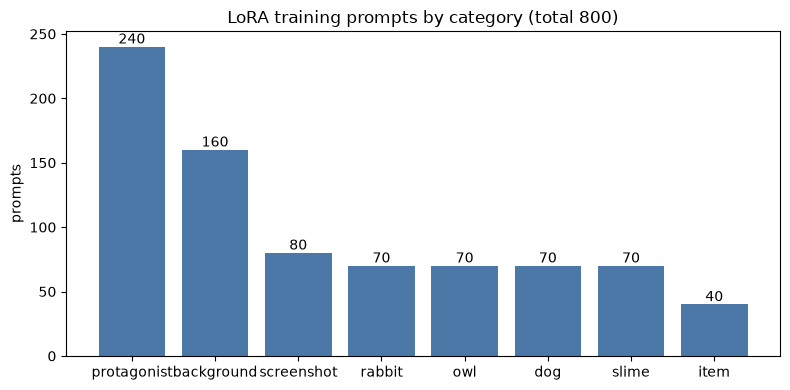

In [17]:
counts = prompts['category'].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(counts.index, counts.values, color='#4C78A8')
ax.bar_label(bars)
ax.set_title(f'LoRA training prompts by category (total {len(prompts)})')
ax.set_ylabel('prompts')
plt.tight_layout()
plt.show()

## API 함수

In [18]:
def anlas():
    r = requests.get(SUB_URL, headers=HEADERS, timeout=30)
    r.raise_for_status()
    s = r.json()['trainingStepsLeft']
    return s['fixedTrainingStepsLeft'] + s['purchasedTrainingSteps']


def ref_base64(path):
    # Risu와 같은 방식: 1472x1472 검은 배경 중앙에 비율 유지로 축소 후 PNG base64
    im = Image.open(path).convert('RGB')
    s = min(1472 / im.width, 1472 / im.height)
    im = im.resize((int(im.width * s), int(im.height * s)), Image.LANCZOS)
    canvas = Image.new('RGB', (1472, 1472), 'black')
    canvas.paste(im, ((1472 - im.width) // 2, (1472 - im.height) // 2))
    buf = io.BytesIO()
    canvas.save(buf, format='PNG')
    return base64.b64encode(buf.getvalue()).decode()


REF_B64 = ref_base64(REF_IMAGE) if USE_PRECISE_REFERENCE else None


def build_body(prompt, seed):
    full = f'{prompt}, {QUALITY_SUFFIX}'
    params = {
        'params_version': 3, 'width': WIDTH, 'height': HEIGHT, 'scale': SCALE, 'sampler': SAMPLER, 'steps': STEPS,
        'n_samples': 1, 'seed': seed, 'noise_schedule': NOISE_SCHEDULE, 'cfg_rescale': 0, 'uncond_scale': 1,
        'ucPreset': 3, 'qualityToggle': False, 'negative_prompt': UC, 'prefer_brownian': True,
        'deliberate_euler_ancestral_bug': False, 'skip_cfg_above_sigma': None, 'legacy': False, 'legacy_v3_extend': False,
        'v4_prompt': {'caption': {'base_caption': full, 'char_captions': []}, 'use_coords': False, 'use_order': True},
        'v4_negative_prompt': {'caption': {'base_caption': UC, 'char_captions': []}, 'legacy_uc': False},
        'reference_image_multiple': [], 'reference_strength_multiple': [],
    }
    if USE_PRECISE_REFERENCE:
        params.update({
            'director_reference_images': [REF_B64],
            'director_reference_descriptions': [{'caption': {'base_caption': 'character&style', 'char_captions': []}, 'legacy_uc': False}],
            'director_reference_information_extracted': [1],
            'director_reference_strength_values': [1],
        })
    return {'input': full, 'model': MODEL, 'action': 'generate', 'parameters': params}


def generate(prompt, seed, retries=3):
    for attempt in range(retries):
        r = requests.post(GEN_URL, headers=HEADERS, json=build_body(prompt, seed), timeout=180)
        if r.status_code == 200:
            # 응답은 image_0.png가 든 zip (Risu processZip, 직접 호출 사례 문서와 동일)
            with zipfile.ZipFile(io.BytesIO(r.content)) as z:
                return z.read(z.namelist()[0])
        # 429(동시 요청 제한)·5xx만 재시도, 그 외(401 키 오류, 400 파라미터 오류)는 바로 중단
        if r.status_code == 429 or r.status_code >= 500:
            time.sleep(10 * (attempt + 1))
            continue
        raise RuntimeError(f'{r.status_code}: {r.text[:300]}')
    raise RuntimeError(f'재시도 {retries}회 실패: {r.status_code} {r.text[:300]}')


def save_log(rec):
    pd.DataFrame([rec]).to_csv(LOG_CSV, mode='a', header=not LOG_CSV.exists(), index=False, encoding='utf-8')

In [22]:
r = requests.get('https://image.novelai.net/user/subscription', headers=HEADERS, timeout=30)
print(r.status_code, r.text[:500])
s = requests.get(SUB_URL, headers=HEADERS, timeout=30).json()
print('tier:', s['tier'], '(3 = Opus) | active:', s['active'], '| Anlas:', anlas())

200 {"tier":3,"active":true,"paymentProcessor":"chargebee","expiresAt":1794445692,"perks":{"maxPriorityActions":1000,"startPriority":10,"contextTokens":8192,"unlimitedMaxPriority":true,"moduleTrainingSteps":10000},"paymentProcessorData":null,"trainingStepsLeft":{"fixedTrainingStepsLeft":10000,"purchasedTrainingSteps":758},"accountType":0,"isGracePeriod":false,"isPaypal":false,"usage":{"percent":100,"purchasedPercent":0,"isNegative":false,"timeUntilNextPercent":7888}}

tier: 3 (3 = Opus) | active: True | Anlas: 10758


## 1장 테스트

전체 생성 전에 1장만 만들어 다음을 확인한다.

- Anlas 차감량 (Precise Reference 사용 시 공식 문서 기준 장당 5 Anlas 추가)
- 결과 PNG의 모델 버전이 기존 이미지(`NovelAI Diffusion V4.5 C02D4F98`)와 같은지
- 그림체가 기존 이미지와 같은지 (기준 이미지와 나란히 표시)

Anlas 780 → 758 (차감 22)
Source: NovelAI Diffusion V4.5 4BDE2A90 | 기존과 다름 (기존 NovelAI Diffusion V4.5 C02D4F98)


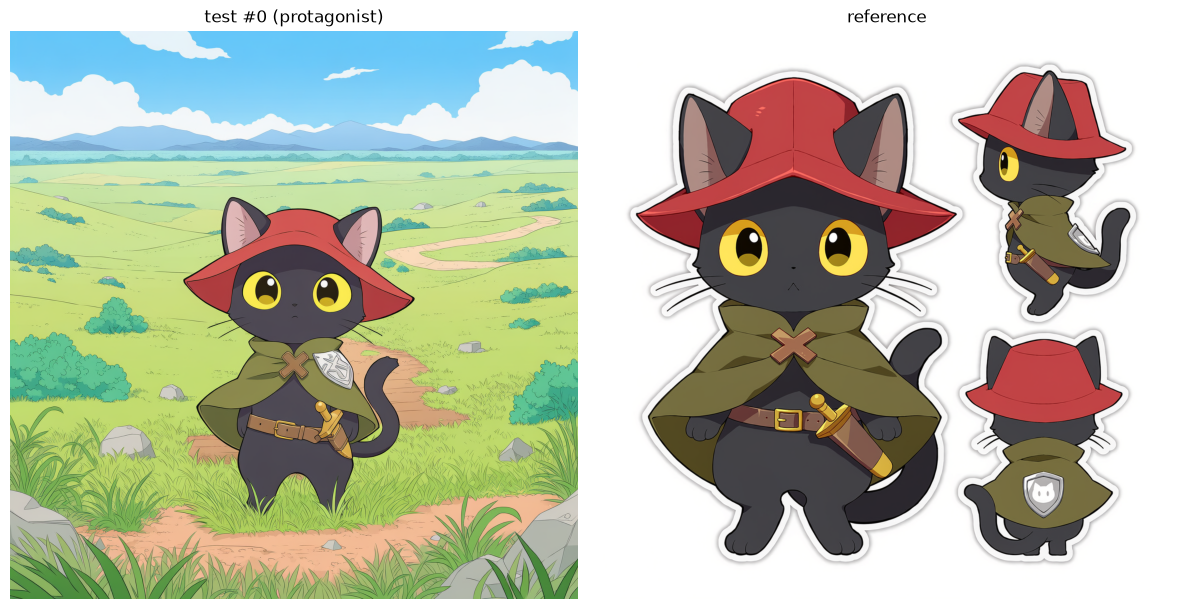

In [20]:
row = prompts.iloc[0]
before = anlas()
png = generate(row['prompt'], int(row['seed']))
after = anlas()
(GEN_DIR / row['file']).write_bytes(png)
test_img = Image.open(io.BytesIO(png))
source = test_img.info.get('Source')
COST_PER_IMAGE = before - after
print(f'Anlas {before} → {after} (차감 {COST_PER_IMAGE})')
print('Source:', source, '| 기존과 같음' if source == EXPECTED_SOURCE else f'| 기존과 다름 (기존 {EXPECTED_SOURCE})')
save_log({'idx': int(row['idx']), 'category': row['category'], 'file': row['file'], 'seed': int(row['seed']),
          'anlas_before': before, 'anlas_after': after, 'source': source, 'time': time.strftime('%Y-%m-%d %H:%M:%S')})

fig, axes = plt.subplots(1, 2 if REF_IMAGE else 1, figsize=(12, 6), squeeze=False)
axes[0, 0].imshow(test_img)
axes[0, 0].set_title(f"test #{row['idx']} ({row['category']})")
axes[0, 0].axis('off')
if REF_IMAGE:
    axes[0, 1].imshow(Image.open(REF_IMAGE))
    axes[0, 1].set_title('reference')
    axes[0, 1].axis('off')
plt.tight_layout()
plt.show()

## 전체 생성

`MAX_ANLAS`에 이번 생성에 쓸 Anlas 상한을 정해야 실행된다. 1장 테스트의 차감량보다 많이 차감된 장이 나오면 바로 멈춘다.

In [23]:
MAX_ANLAS = 8000
assert MAX_ANLAS is not None, 'MAX_ANLAS(이번 생성에 쓸 Anlas 상한)를 정해야 함'
print(f'예상 사용량: {COST_PER_IMAGE} x {len(prompts)} = {COST_PER_IMAGE * len(prompts)} Anlas')

done = set(pd.read_csv(LOG_CSV)['idx']) if LOG_CSV.exists() else set()
start = anlas()
for _, row in prompts.iterrows():
    if row['idx'] in done and (GEN_DIR / row['file']).exists():
        continue
    before = anlas()
    if start - before >= MAX_ANLAS:
        print('Anlas 상한 도달, 중단')
        break
    try:
        png = generate(row['prompt'], int(row['seed']))
    except RuntimeError as e:
        print(f"#{row['idx']} 실패: {e}")
        break
    after = anlas()
    (GEN_DIR / row['file']).write_bytes(png)
    source = Image.open(io.BytesIO(png)).info.get('Source')
    save_log({'idx': int(row['idx']), 'category': row['category'], 'file': row['file'], 'seed': int(row['seed']),
              'anlas_before': before, 'anlas_after': after, 'source': source, 'time': time.strftime('%Y-%m-%d %H:%M:%S')})
    print(f"#{row['idx']:4d} {row['category']:11s} Anlas {before}→{after}", flush=True)
    # 테스트보다 많이 차감되면 무료/추가 비용 조건이 바뀐 것이라 멈춤
    if before - after > COST_PER_IMAGE:
        print(f'차감 {before - after} > 테스트 {COST_PER_IMAGE}, 중단')
        break

예상 사용량: 22 x 800 = 17600 Anlas
#   1 protagonist Anlas 10758→10753
#   2 protagonist Anlas 10753→10748
#   3 protagonist Anlas 10748→10743
#   4 protagonist Anlas 10743→10738
#   5 protagonist Anlas 10738→10733
#   6 protagonist Anlas 10733→10728
#   7 protagonist Anlas 10728→10723
#   8 protagonist Anlas 10723→10718
#   9 protagonist Anlas 10718→10713
#  10 protagonist Anlas 10713→10708
#  11 protagonist Anlas 10708→10703
#  12 protagonist Anlas 10703→10698
#  13 protagonist Anlas 10698→10693
#  14 protagonist Anlas 10693→10688
#  15 protagonist Anlas 10688→10683
#  16 protagonist Anlas 10683→10678
#  17 protagonist Anlas 10678→10673
#  18 protagonist Anlas 10673→10668
#  19 protagonist Anlas 10668→10663
#  20 protagonist Anlas 10663→10658
#  21 protagonist Anlas 10658→10653
#  22 protagonist Anlas 10653→10648
#  23 protagonist Anlas 10648→10643
#  24 protagonist Anlas 10643→10638
#  25 protagonist Anlas 10638→10633
#  26 protagonist Anlas 10633→10628
#  27 protagonist Anlas 10628→106

## 생성 결과 확인

생성 800 / 800장, 총 차감 4017 Anlas, 모델 버전 {'NovelAI Diffusion V4.5 4BDE2A90': 800}


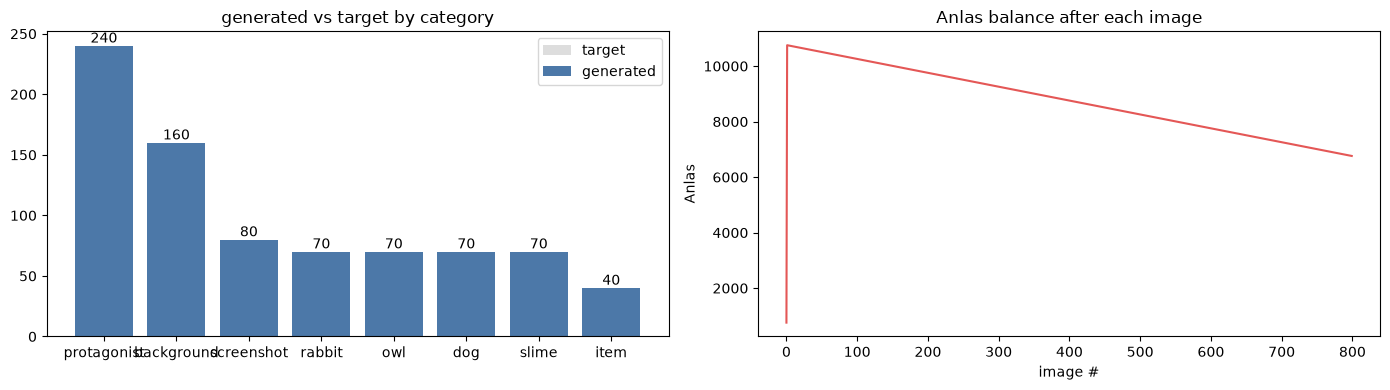

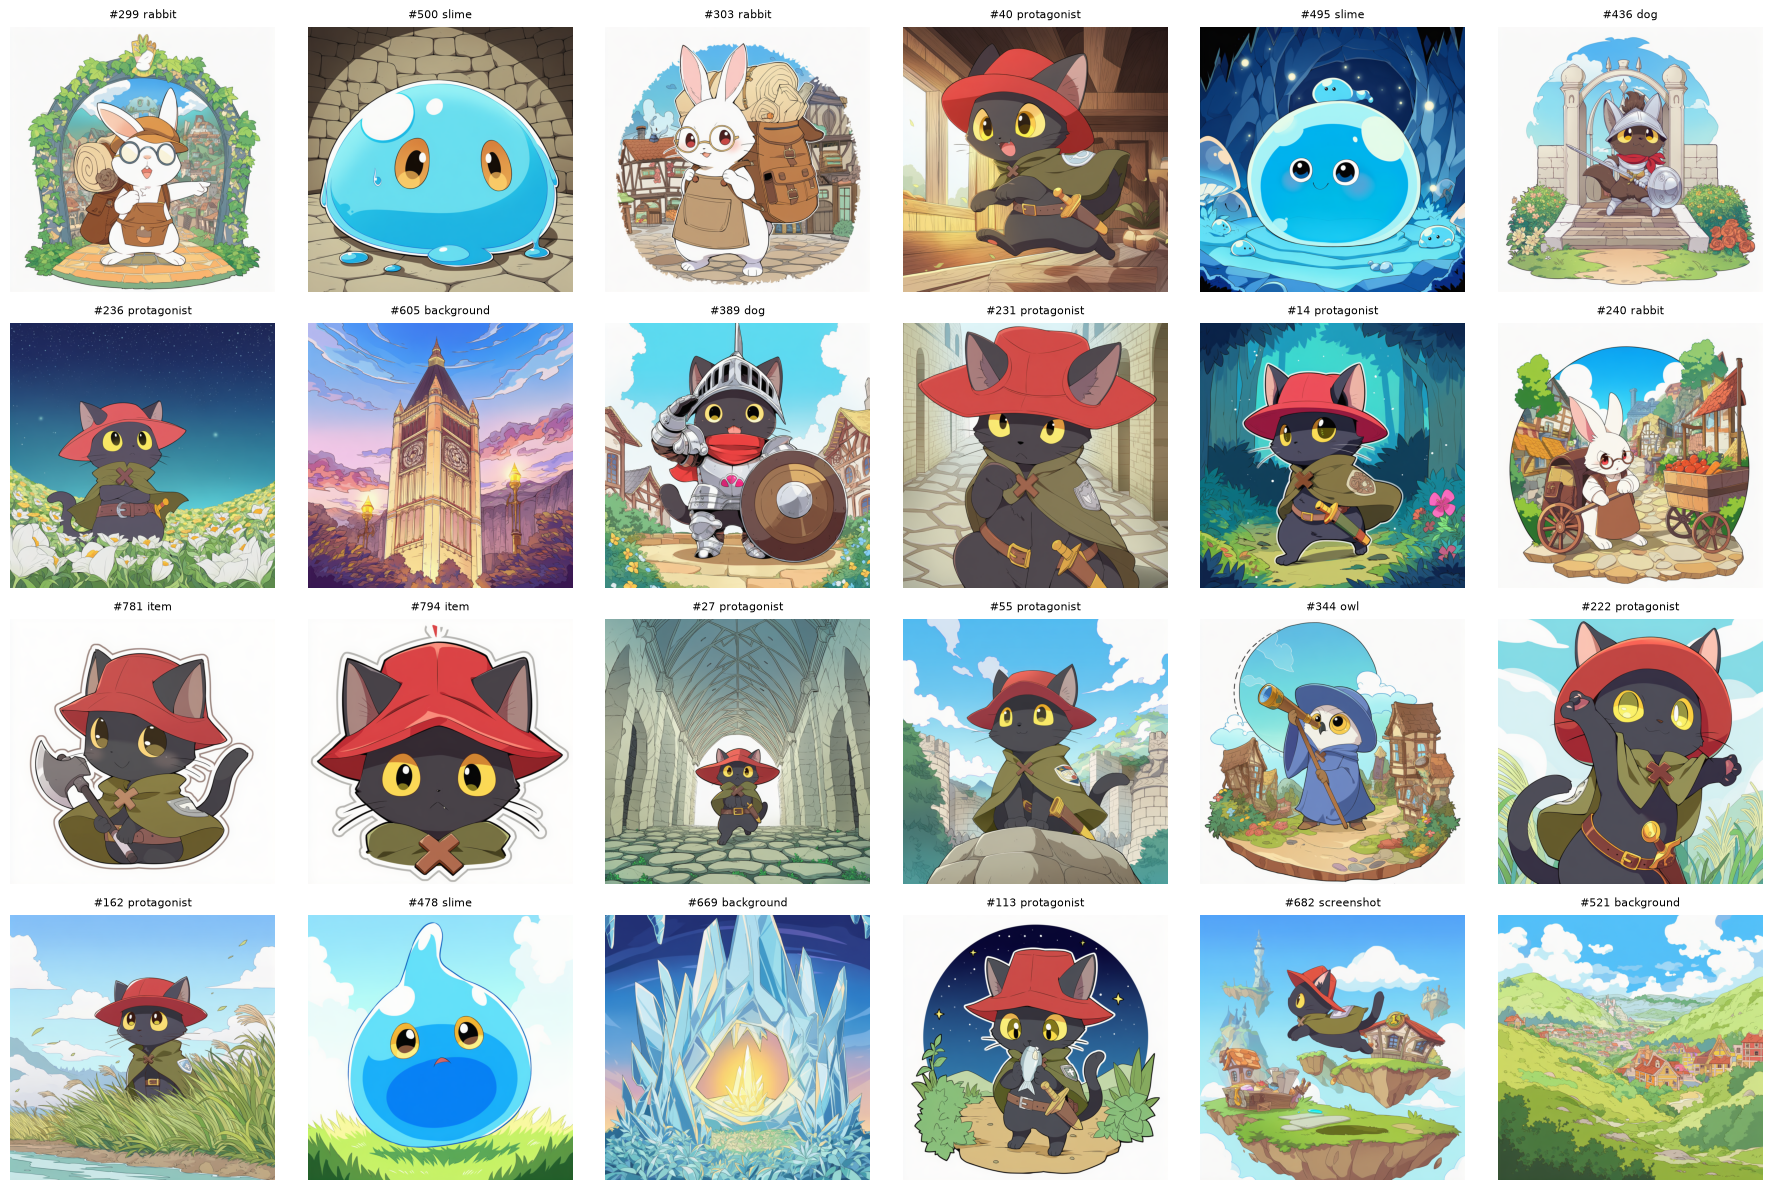

In [24]:
log = pd.read_csv(LOG_CSV).drop_duplicates('idx', keep='last')
log['cost'] = log['anlas_before'] - log['anlas_after']
print(f"생성 {len(log)} / {len(prompts)}장, 총 차감 {log['cost'].sum()} Anlas, 모델 버전 {log['source'].value_counts().to_dict()}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
target = prompts['category'].value_counts()
made = log['category'].value_counts().reindex(target.index, fill_value=0)
a1.bar(target.index, target.values, color='#DDDDDD', label='target')
bars = a1.bar(made.index, made.values, color='#4C78A8', label='generated')
a1.bar_label(bars)
a1.legend()
a1.set_title('generated vs target by category')
a2.plot(range(len(log)), log['anlas_after'].values, color='#E45756')
a2.set_title('Anlas balance after each image')
a2.set_xlabel('image #')
a2.set_ylabel('Anlas')
plt.tight_layout()
plt.show()

sample = log.sample(min(24, len(log)), random_state=0)
fig, axes = plt.subplots(4, 6, figsize=(18, 12))
for ax in axes.flat:
    ax.axis('off')
for ax, (_, r) in zip(axes.flat, sample.iterrows()):
    ax.imshow(Image.open(GEN_DIR / r['file']))
    ax.set_title(f"#{r['idx']} {r['category']}", fontsize=8)
plt.tight_layout()
plt.show()